# Credit risk scoring on the German Credit data

**Question a lender asks:** *Which applicants should we approve, if approving someone who later defaults costs us much more than turning away someone who would have repaid?*

This notebook builds three credit-risk models, compares them fairly, and then does the step many tutorials skip: it picks an **approval cut-off using the business cost of each mistake**, not the default 0.5.

**Data:** Statlog (German Credit Data), Hofmann (1994), UCI Machine Learning Repository, licensed CC BY 4.0, DOI 10.24432/C5NC77. 1,000 loan applicants, 20 attributes, 700 good and 300 bad credit outcomes. The notebook loads the copy bundled with the `scorecardpy` package, so no data file is stored in this repo.

**Cost matrix (from the UCI documentation):** approving an applicant who turns out bad costs **5**; rejecting an applicant who would have been good costs **1**.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("scorecardpy") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scorecardpy"])

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scorecardpy as sc

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

## 1. Load and inspect the data

In [2]:
df = sc.germancredit()
df["bad"] = (df["creditability"] == "bad").astype(int)   # 1 = bad credit outcome
df = df.drop(columns="creditability")

print("Rows, columns:", df.shape)
print()
print(df["bad"].map({0: "good", 1: "bad"}).value_counts(normalize=True).round(3))

Rows, columns: (1000, 21)

bad
good    0.7
bad     0.3
Name: proportion, dtype: float64


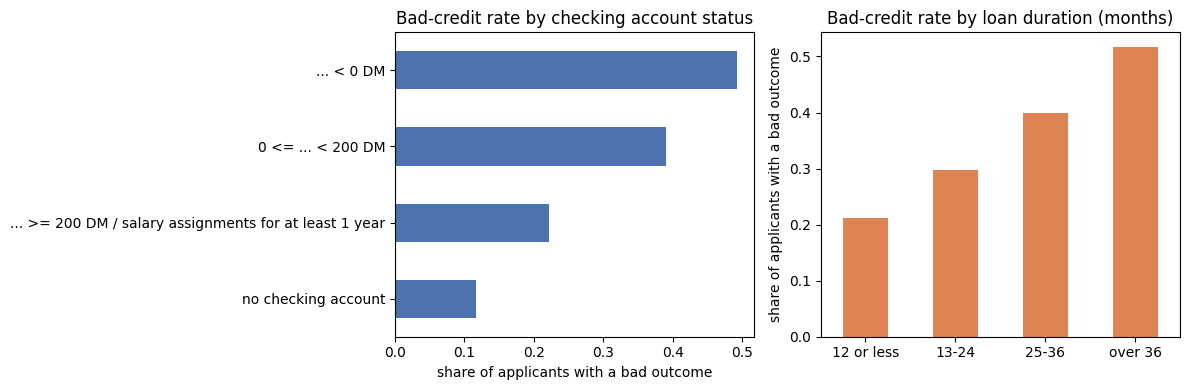

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

(df.groupby("status_of_existing_checking_account", observed=True)["bad"].mean()
   .sort_values().plot.barh(ax=ax[0], color="#4c72b0"))
ax[0].set_title("Bad-credit rate by checking account status")
ax[0].set_xlabel("share of applicants with a bad outcome")
ax[0].set_ylabel("")

bands = pd.cut(df["duration_in_month"], [0, 12, 24, 36, 100], labels=["12 or less", "13-24", "25-36", "over 36"])
df.groupby(bands, observed=True)["bad"].mean().plot.bar(ax=ax[1], color="#dd8452", rot=0)
ax[1].set_title("Bad-credit rate by loan duration (months)")
ax[1].set_ylabel("share of applicants with a bad outcome")
ax[1].set_xlabel("")

plt.tight_layout(); plt.show()

## 2. Choose features, and leave out protected characteristics

Two attributes describe who the applicant *is* rather than their finances: `personal_status_and_sex` and `foreign_worker`. A lender should not score people on these, so they are **excluded from every model**. Other features can still act as proxies for them, so this reduces the problem rather than removing it. The limitations section comes back to this.

In [4]:
PROTECTED = ["personal_status_and_sex", "foreign_worker"]
X = df.drop(columns=["bad"] + PROTECTED)
y = df["bad"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"{len(num_cols)} numeric and {len(cat_cols)} categorical features used")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape[0], "applicants | Test:", X_test.shape[0], "applicants (held back until the end)")

7 numeric and 11 categorical features used
Train: 800 applicants | Test: 200 applicants (held back until the end)


## 3. Compare three models using the training set only

Out-of-fold predictions (5-fold cross-validation) give every training applicant a score from a model that never saw them. The best model is chosen here, **before the test set is touched**.

In [5]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

models = {
    "Logistic regression": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, C=0.5))]),
    "Random forest": Pipeline([("pre", pre), ("clf", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("pre", pre), ("clf", HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}
rows = []
for name, model in models.items():
    p = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof[name] = p
    rows.append({"model": name, "out_of_fold_AUC": round(roc_auc_score(y_train, p), 3)})

cv_table = pd.DataFrame(rows).sort_values("out_of_fold_AUC", ascending=False).reset_index(drop=True)
best = cv_table.loc[0, "model"]
print(cv_table.to_string(index=False))
print(f"\nSelected on training data: {best}")

              model  out_of_fold_AUC
      Random forest            0.791
  Gradient boosting            0.785
Logistic regression            0.766

Selected on training data: Random forest


## 4. Pick the approval cut-off from the business cost

A model outputs a probability of being a bad credit. The lender still has to choose the probability above which it rejects. With a 5:1 cost ratio the cheapest cut-off is far below 0.5, because wrongly approving a bad applicant is five times as expensive as wrongly rejecting a good one. The cut-off is chosen on the **training-set out-of-fold predictions only**.

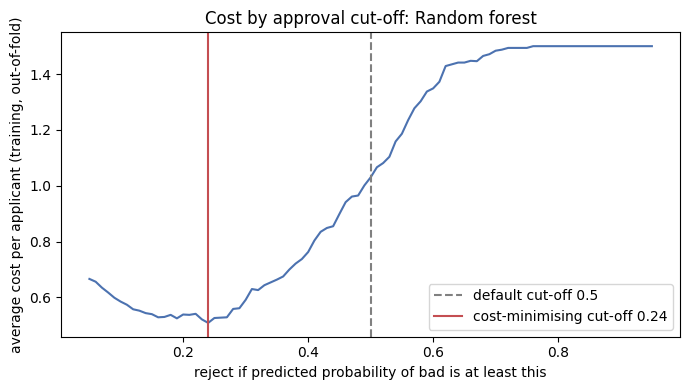

Chosen cut-off (training data only): 0.24


In [6]:
COST_APPROVE_BAD = 5    # approve an applicant who then goes bad
COST_REJECT_GOOD = 1    # reject an applicant who would have repaid

def cost_per_applicant(y_true, p_bad, threshold):
    y_true = np.asarray(y_true)
    reject = p_bad >= threshold
    approved_bad = ((~reject) & (y_true == 1)).sum()
    rejected_good = (reject & (y_true == 0)).sum()
    return (COST_APPROVE_BAD * approved_bad + COST_REJECT_GOOD * rejected_good) / len(y_true)

thresholds = np.linspace(0.05, 0.95, 91)
train_cost = np.array([cost_per_applicant(y_train, oof[best], t) for t in thresholds])
t_star = float(thresholds[train_cost.argmin()])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, train_cost, color="#4c72b0")
plt.axvline(0.5, color="grey", linestyle="--", label="default cut-off 0.5")
plt.axvline(t_star, color="#c44e52", label=f"cost-minimising cut-off {t_star:.2f}")
plt.xlabel("reject if predicted probability of bad is at least this")
plt.ylabel("average cost per applicant (training, out-of-fold)")
plt.title(f"Cost by approval cut-off: {best}")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Chosen cut-off (training data only): {t_star:.2f}")

## 5. Final check on the held-back test set

Test AUC for every model (selection was already made in section 3):
  Logistic regression  0.805
  Random forest        0.795
  Gradient boosting    0.794



Random forest: test AUC 0.795, 95% bootstrap interval 0.722 to 0.864


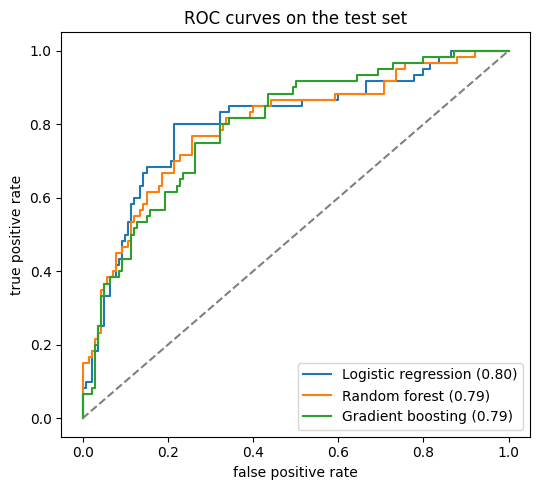

In [7]:
final = models[best].fit(X_train, y_train)
test_p = {name: m.fit(X_train, y_train).predict_proba(X_test)[:, 1] for name, m in models.items()}

print("Test AUC for every model (selection was already made in section 3):")
for name, p in test_p.items():
    print(f"  {name:<20} {roc_auc_score(y_test, p):.3f}")

# How certain is the chosen model's AUC with only 200 test applicants? Bootstrap the test set.
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy(); pb = test_p[best]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    boot.append(roc_auc_score(yt[idx], pb[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\n{best}: test AUC {roc_auc_score(yt, pb):.3f}, 95% bootstrap interval {lo:.3f} to {hi:.3f}")

plt.figure(figsize=(5.5, 5))
for name, p in test_p.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.2f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("ROC curves on the test set"); plt.legend(); plt.tight_layout(); plt.show()

### What the cut-off does in money terms

In [8]:
def policy_row(label, threshold):
    reject = pb >= threshold
    approved = ~reject
    return {
        "policy": label,
        "approval rate": round(approved.mean(), 3),
        "bad rate among approved": round(yt[approved].mean(), 3) if approved.any() else float("nan"),
        "cost per applicant": round(cost_per_applicant(yt, pb, threshold), 3),
    }

policy_table = pd.DataFrame([
    policy_row("Approve everyone", 1.01),
    policy_row("Model, default cut-off 0.50", 0.50),
    policy_row(f"Model, cost-based cut-off {t_star:.2f}", t_star),
])
print(policy_table.to_string(index=False))
print()
print(f"Test set: {len(yt)} applicants, of whom {int(yt.sum())} were bad credits.")

                        policy  approval rate  bad rate among approved  cost per applicant
              Approve everyone          1.000                    0.300               1.500
   Model, default cut-off 0.50          0.845                    0.219               0.965
Model, cost-based cut-off 0.24          0.415                    0.096               0.525

Test set: 200 applicants, of whom 60 were bad credits.


## 6. Which inputs drive the decisions?

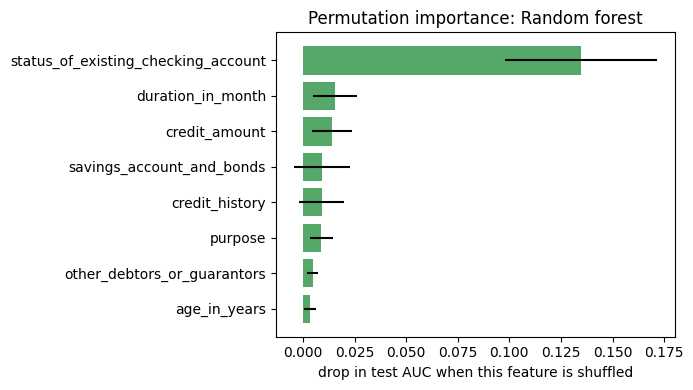

                            feature  mean_drop_in_AUC   std
status_of_existing_checking_account             0.135 0.037
                  duration_in_month             0.016 0.011
                      credit_amount             0.014 0.010
          savings_account_and_bonds             0.009 0.014
                     credit_history             0.009 0.011
                            purpose             0.009 0.006
        other_debtors_or_guarantors             0.005 0.003
                       age_in_years             0.003 0.003


In [9]:
imp = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
imp_df = (pd.DataFrame({"feature": X_test.columns, "mean_drop_in_AUC": imp.importances_mean,
                        "std": imp.importances_std})
          .sort_values("mean_drop_in_AUC", ascending=False))

top = imp_df.head(8).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["mean_drop_in_AUC"], xerr=top["std"], color="#55a868")
plt.xlabel("drop in test AUC when this feature is shuffled")
plt.title(f"Permutation importance: {best}")
plt.tight_layout(); plt.show()
print(imp_df.head(8).round(3).to_string(index=False))

## 7. What this shows

* **The three models are close.** Out-of-fold AUC was 0.791 for the random forest, 0.785 for gradient boosting and 0.766 for logistic regression. On the test set the order flipped slightly (logistic regression 0.805, random forest 0.795, gradient boosting 0.794). With 200 test applicants the random forest's 95% interval runs from 0.722 to 0.864, so these gaps are within noise. A plain logistic regression would be a defensible choice here because it is easier to explain to a customer or a regulator.
* **The cut-off mattered far more than the model.** Approving everyone costs 1.50 per applicant on the test set. The default 0.50 cut-off costs 0.965. The cost-based cut-off of 0.24 (chosen on training data only) costs 0.525.
* **That saving has a price.** The 0.24 cut-off approves only 41.5% of applicants. The bad rate among those approved falls to 9.6%, against 30% in the full test set, but many good customers are turned away. A real lender would weigh the lost revenue from those customers, which this cost matrix ignores.
* **One input does most of the work.** Shuffling checking account status drops test AUC by about 0.135. Every other feature drops it by 0.02 or less.

## 8. Limitations

* **Old, small data.** 1,000 applicants, from an era and country very different from a modern UK lender. UCI's own South German Credit page says data is from 1973 to 1975 and that the Statlog coding information has errors, so category labels should be read with care.
* **The 5:1 cost ratio is a documented convention in this dataset, not any lender's real economics.** Change `COST_APPROVE_BAD` and `COST_REJECT_GOOD` in section 4 to see how sensitive the cut-off is.
* **Only 200 test applicants (60 bad).** Cost and approval figures from this split are uncertain, and I did not put an interval on them.
* **Fairness is only partly handled.** Two protected attributes are excluded, but other features can still act as proxies, and I did not measure approval or error rates across groups.
* **Probabilities were not calibrated**, so the cut-off is a ranking decision, not a statement that a given applicant has a 24% chance of default.

**Next steps:** repeat the workflow on a larger modern dataset (for example Home Credit Default Risk), add calibration, and audit error rates across groups.